https://karpathy.github.io/2026/02/12/microgpt/

In [1]:
from helpers import *

causal attention
```
x ──┬──► LN ─► Attention ─┐
    └─────────────────────(+)──► x ──┬──► LN ─► MLP ─┐
                                     └───────────────(+)──► x (to next block)
```

In [40]:
class LayerNorm:
	def __init__(self, dim, eps=1e-5, momentum=0.1):
		self.eps = eps
		self.momentum = momentum
		self.training = True # turn off later

		self.gamma = torch.ones(dim)
		self.beta = torch.zeros(dim)

	def __call__(self, x):
		# since each batch is independent, not intercorrelated, eval + training behave the same
		xmean = x.mean(-1, keepdim=True) # MAIN difference, mean over last dimension instead batch dim
		xvar = x.var(-1, keepdim=True) # mean, var of entire embedding
		
		xhat = (x - xmean) / (xvar**0.5 + self.eps)
		self.out = self.gamma * xhat + self.beta
		return self.out
		
	def parameters(self):
		return [self.beta, self.gamma]

class Dropout:
	def __init__(self, p):
		self.p = p
	def __call__(self, x, training):

		# learns redundant features so you don't rely on any single one neuron too much
		if not training or self.p == 0:
			return x
		
		# [0, 1, 1, 0, 0] etc
		mask = (torch.rand_like(x) > self.p).float() 

		# E = p * 0 + (1-p) * 1
		# The next layer's weights were learned for inputs about (1-p) as large.
		# At evaluation, it gets inputs 1/(1-p) bigger, so its outputs are off and compounds
		self.out = x * mask / (1-self.p)
		return self.out

class ReLU:
	def __call__(self, x):
		return torch.relu(x)


class CausalAttentionModel(nn.Module):
	def __init__(self, batch=32, embedding_size=64, nhidden=64):
		super().__init__()

		self.B, self.T, self.C = batch, context_size, embedding_size
		self.d = nhidden

		self.embeddings = torch.randn(27, self.C, requires_grad=True)
		self.pos = torch.randn(self.T, self.C, requires_grad=True) 

		self.Q = (torch.randn(self.C, self.d) / self.C**0.5).requires_grad_()
		self.K = (torch.randn(self.C, self.d) / self.C**0.5).requires_grad_()
		self.V = (torch.randn(self.C, self.d) / self.C**0.5).requires_grad_()

		# ONLY if d != C, but here its redundant
		self.W0 = (torch.randn(self.d, self.C) / self.C**0.5).requires_grad_()

		self.l1 = (torch.randn(self.C, self.C*4) / self.C**0.5).requires_grad_()
		self.relu1 = ReLU()
		self.l2 = (torch.randn(self.C*4, self.C) / self.C**0.5).requires_grad_()

		self.ln1 = LayerNorm(self.C)
		self.ln2 = LayerNorm(self.C)
		self.ln3 = LayerNorm(self.C)
		self.dropout = Dropout(0.1)

		self.head = (torch.randn(self.C, 27) / self.d**0.5).requires_grad_()


	def forward(self, tokens):
		# tokens: (B, T)

		# emb: (B, T, C) ~ (batch, idx in ctx, letter_emb)
		emb = self.embeddings[tokens]
		# pos: (T, C)
		pos = self.pos[torch.arange(self.T)]

		# h: (B, T, C)
		h = emb + pos

		# LayerNorm1
		h = self.ln1(h)

		# (B, T, C) @ (B, C, d) = (B, T, d)
		q, k = h @ self.Q, h @ self.K

		# (BTC) @ (BCd) = BTd
		v = h @ self.V

		# sftmx( (B, T, d) @ (B, d, T) / n)
		att = torch.softmax(q @ k.mT / self.d**0.5, dim=-1)

		# (B, T, T) @ (B, T, d) = (B, T, d)
		z = att @ v

		# if d != C, then well need a linear layer to get to BTC here
		# z = z @ self.W0
		
		# (B, T, C)
		z = h + z # residual with embedding

		# LayerNorm 2: (BTC)
		z = self.ln2(z)

		# MLP
		# (BTC) @ (C, C*4) = (B,T,C*4)
		z = z @ self.l1
		z = self.relu1(z)
		# (B,T,C*4) * (C*4,C) = BTC
		z = z @ self.l2
		z = self.dropout(z, training=True)

		# LayerNorm: BTC
		z = self.ln3(z)

		# (B, T, C) * (C, 27) = (B, T, 27)
		self.out = z @ self.head # all tokens + new predicted token

		return self.out
	
	def opt(self):
		params = [
			self.embeddings, self.pos, 
			self.Q, self.K, self.V, self.head,
			self.l1, self.l2
		]
		params.extend(self.ln1.parameters())
		params.extend(self.ln2.parameters())
		params.extend(self.ln3.parameters())
		return torch.optim.AdamW(params) 

mymodel = CausalAttentionModel()

In [41]:
criterion = nn.CrossEntropyLoss()
optimizer = mymodel.opt()

lossi = []

for i in range(10000):
	ixs = torch.randint(0, Xtrain.shape[0], (batchsize,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]

	logits = mymodel(ctx)

	loss = criterion(logits[:, -1, :], target)

	optimizer.zero_grad()
	loss.backward()
	optimizer.step()

	lossi.append(loss.item())

print(loss.item())

1.7666157484054565


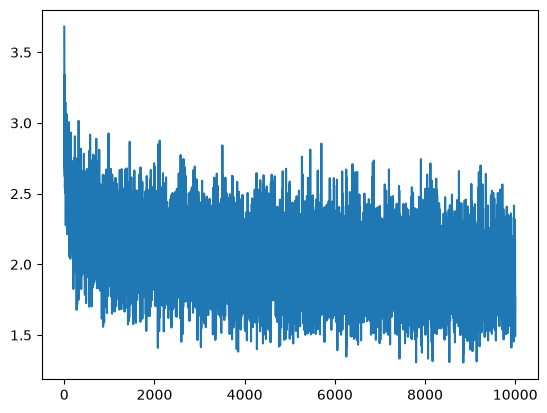

In [42]:
plt.plot(lossi)

In [44]:
alpha = "abcdefghijklmnopqrstuvwxyz."

mymodel.eval() 

for i in range(20):
	ctx = torch.tensor([0] * context_size).unsqueeze(0)
	name = ""

	while len(name) < 20:
		logits = mymodel(ctx)
		probs = torch.softmax(logits[:, -1, :], axis=1)
		cidx = torch.multinomial(probs, 1)
		c = alpha[cidx.item()]; name += c
		if c == ".":
			break
		ctx = torch.cat([ctx[:, 1:], cidx], dim=1)
	
	print(name)

jazlyn.
milkyndra.
haddy.
imandra.
galey.
zariynna.
mariley.
kaletn.
elyn.
ilee.
ealyn.
emma.
lakya.
jennettin.
akheline.
.
aryleigh.
ryel.
syn.
fin.
